<a href="https://colab.research.google.com/github/jasmineesfw/AnalisisdanVisualisasiData-Kelompok1/blob/main/Analisis_Data_Penjualan_Kelompok_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan grafik
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Library berhasil diimpor!")

Library berhasil diimpor!


In [11]:
from google.colab import files

uploaded = files.upload()

# Membaca dataset
df = pd.read_csv('ecommerce_sales_analytics_5000.csv')

print("Dataset berhasil dimuat!")

Saving ecommerce_sales_analytics_5000.csv to ecommerce_sales_analytics_5000 (2).csv
Dataset berhasil dimuat!


In [12]:
# Menampilkan 5 data pertama
print("5 Data Pertama:")
display(df.head())

# Informasi dataset
print("\nInformasi Dataset:")
df.info()

# Ukuran dataset
print("\nUkuran Dataset:")
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

# Statistik deskriptif awal
print("\nStatistik Deskriptif:")
display(df.describe())

5 Data Pertama:


,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56



Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   object 
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   object 
 4   region            5000 non-null   object 
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   object 
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), object(4)
memory usage: 468.9+ KB

Ukuran Dataset:
Jumlah baris: 5000
Jumlah kolom: 12

Statistik Deskriptif:


,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,1443.520003,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,10001.000000,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


In [13]:
# Mengecek data kosong
print("Jumlah Data Kosong:")
print(df.isnull().sum())

# Mengecek data duplikat
print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

# Menghapus data duplikat jika ada
df = df.drop_duplicates()

# Mengubah format tanggal
df['order_date'] = pd.to_datetime(df['order_date'])

print("\nPembersihan Data Selesai!")
print("Jumlah data setelah dibersihkan:", len(df))

Jumlah Data Kosong:
order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

Jumlah Data Duplikat:
0

Pembersihan Data Selesai!
Jumlah data setelah dibersihkan: 5000


In [14]:
# Statistik deskriptif
print("=== STATISTIK DESKRIPTIF ===")

display(df[['quantity', 'unit_price', 'discount',
            'delivery_days', 'customer_rating', 'revenue']].describe())

# Total dan rata-rata penjualan
total_penjualan = df['revenue'].sum()
rata_rata_transaksi = df['revenue'].mean()
median_transaksi = df['revenue'].median()
standar_deviasi = df['revenue'].std()

print("=== RINGKASAN PENJUALAN ===")
print(f"Total Penjualan       : Rp {total_penjualan:,.2f}")
print(f"Rata-rata Transaksi   : Rp {rata_rata_transaksi:,.2f}")
print(f"Median Transaksi      : Rp {median_transaksi:,.2f}")
print(f"Standar Deviasi       : Rp {standar_deviasi:,.2f}")

kategori_terlaris = df.groupby('product_category')['revenue'].sum().idxmax()
penjualan_kategori = df.groupby('product_category')['revenue'].sum().max()

print("Kategori Terlaris:", kategori_terlaris)
print(f"Total Penjualan: Rp {penjualan_kategori:,.2f}")

wilayah_teratas = df.groupby('region')['revenue'].sum().idxmax()
penjualan_wilayah = df.groupby('region')['revenue'].sum().max()

print("Wilayah dengan Penjualan Tertinggi:", wilayah_teratas)
print(f"Total Penjualan: Rp {penjualan_wilayah:,.2f}")

rating_rata_rata = df['customer_rating'].mean()

print(f"Rating Rata-rata Pelanggan: {rating_rata_rata:.2f} / 5")

=== STATISTIK DESKRIPTIF ===


,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


=== RINGKASAN PENJUALAN ===
Total Penjualan       : Rp 5,109,775.74
Rata-rata Transaksi   : Rp 1,021.96
Median Transaksi      : Rp 796.65
Standar Deviasi       : Rp 825.58
Kategori Terlaris: Electronics
Total Penjualan: Rp 1,829,899.22
Wilayah dengan Penjualan Tertinggi: West
Total Penjualan: Rp 1,345,582.16
Rating Rata-rata Pelanggan: 2.97 / 5


=== LAPORAN ANALISIS PENJUALAN ===
Total Penjualan       : Rp 5,109,775.74
Rata-rata Transaksi   : Rp 1,021.96
Median Transaksi      : Rp 796.65
Standar Deviasi       : Rp 825.58
Kategori Terlaris     : Electronics
Kategori Revenue      : Electronics
Wilayah Teratas       : West
Rating Rata-rata      : 2.97 / 5


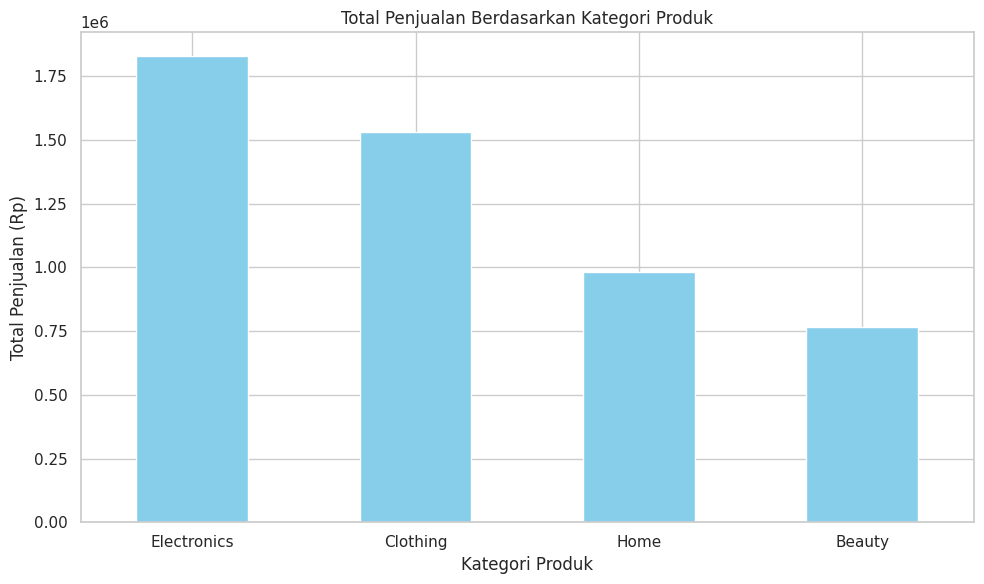

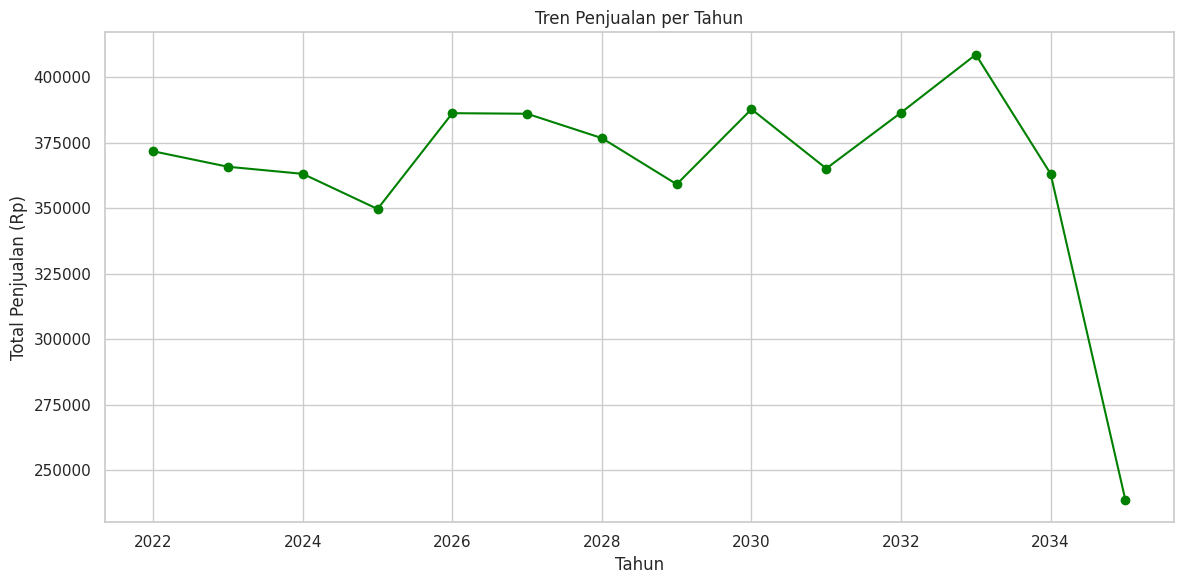

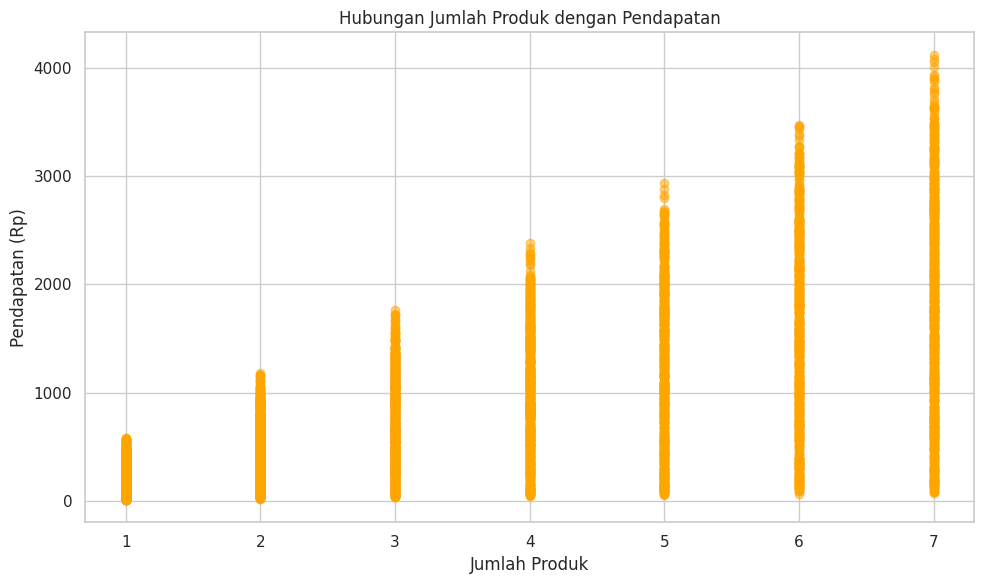

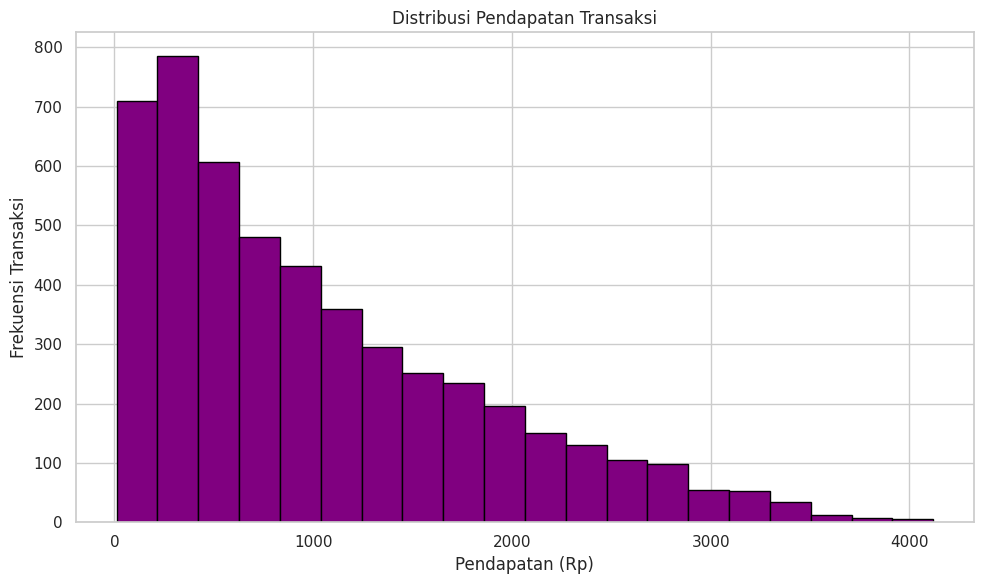

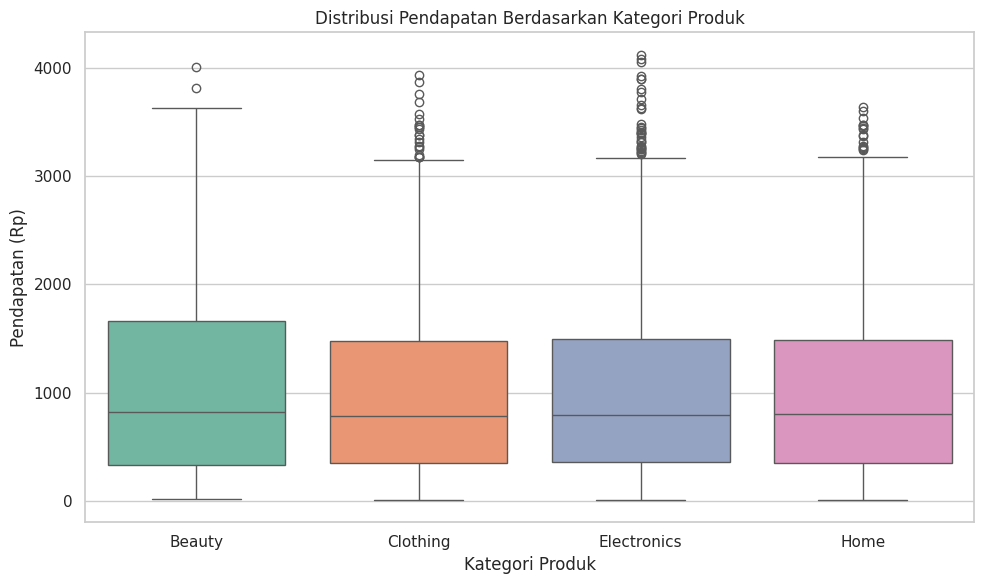

In [15]:
# Kategori dengan jumlah produk terjual terbanyak
kategori_kuantitas = df.groupby('product_category')['quantity'].sum().idxmax()

# Kategori dengan pendapatan tertinggi
kategori_revenue = df.groupby('product_category')['revenue'].sum().idxmax()

# Wilayah dengan pendapatan tertinggi
wilayah_revenue = df.groupby('region')['revenue'].sum().idxmax()

# Membuat ringkasan
print("=== LAPORAN ANALISIS PENJUALAN ===")
print(f"Total Penjualan       : Rp {total_penjualan:,.2f}")
print(f"Rata-rata Transaksi   : Rp {rata_rata_transaksi:,.2f}")
print(f"Median Transaksi      : Rp {median_transaksi:,.2f}")
print(f"Standar Deviasi       : Rp {standar_deviasi:,.2f}")
print(f"Kategori Terlaris     : {kategori_kuantitas}")
print(f"Kategori Revenue      : {kategori_revenue}")
print(f"Wilayah Teratas       : {wilayah_revenue}")
print(f"Rating Rata-rata      : {rating_rata_rata:.2f} / 5")

# Menghitung total revenue setiap kategori
penjualan_kategori = df.groupby('product_category')['revenue'].sum()
penjualan_kategori = penjualan_kategori.sort_values(ascending=False)

# Membuat Bar Chart
plt.figure(figsize=(10, 6))
penjualan_kategori.plot(kind='bar', color='skyblue')

plt.title('Total Penjualan Berdasarkan Kategori Produk')
plt.xlabel('Kategori Produk')
plt.ylabel('Total Penjualan (Rp)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Mengelompokkan penjualan berdasarkan tahun
df['year'] = df['order_date'].dt.year

penjualan_tahunan = df.groupby('year')['revenue'].sum()

# Membuat Line Chart
plt.figure(figsize=(12, 6))
plt.plot(
    penjualan_tahunan.index,
    penjualan_tahunan.values,
    marker='o',
    color='green'
)

plt.title('Tren Penjualan per Tahun')
plt.xlabel('Tahun')
plt.ylabel('Total Penjualan (Rp)')
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

plt.scatter(
    df['quantity'],
    df['revenue'],
    alpha=0.5,
    color='orange'
)

plt.title('Hubungan Jumlah Produk dengan Pendapatan')
plt.xlabel('Jumlah Produk')
plt.ylabel('Pendapatan (Rp)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

plt.hist(
    df['revenue'],
    bins=20,
    color='purple',
    edgecolor='black'
)

plt.title('Distribusi Pendapatan Transaksi')
plt.xlabel('Pendapatan (Rp)')
plt.ylabel('Frekuensi Transaksi')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='product_category',
    y='revenue',
    hue='product_category',
    palette='Set2',
    legend=False
)

plt.title('Distribusi Pendapatan Berdasarkan Kategori Produk')
plt.xlabel('Kategori Produk')
plt.ylabel('Pendapatan (Rp)')
plt.tight_layout()
plt.show()

In [16]:
# Menghitung kuartil
Q1 = df['revenue'].quantile(0.25)
Q3 = df['revenue'].quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Menentukan batas outlier
batas_bawah = Q1 - (1.5 * IQR)
batas_atas = Q3 + (1.5 * IQR)

# Mengidentifikasi outlier
outlier = df[
    (df['revenue'] < batas_bawah) |
    (df['revenue'] > batas_atas)
]

print("=== DETEKSI OUTLIER ===")
print(f"Q1             : {Q1:.2f}")
print(f"Q3             : {Q3:.2f}")
print(f"IQR            : {IQR:.2f}")
print(f"Batas Bawah    : {batas_bawah:.2f}")
print(f"Batas Atas     : {batas_atas:.2f}")
print(f"Jumlah Outlier : {len(outlier)}")

print("\nContoh Data Outlier:")
display(outlier.head(10))

=== DETEKSI OUTLIER ===
Q1             : 354.53
Q3             : 1515.69
IQR            : 1161.16
Batas Bawah    : -1387.22
Batas Atas     : 3257.43
Jumlah Outlier : 67

Contoh Data Outlier:


,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue,year
39,10040,2022-02-09,1474,Home,North,7,584.36,0.11,Card,6,1.3,3640.56,2022
69,10070,2022-03-11,1241,Beauty,East,7,567.75,0.16,Card,1,4.5,3338.37,2022
102,10103,2022-04-13,1201,Clothing,West,6,586.65,0.02,COD,8,4.1,3449.50,2022
126,10127,2022-05-07,1379,Clothing,South,7,506.18,0.02,Wallet,7,2.9,3472.39,2022
157,10158,2022-06-07,1779,Electronics,North,7,571.07,0.02,COD,10,4.5,3917.54,2022
178,10179,2022-06-28,1768,Electronics,North,7,598.63,0.19,Card,7,1.8,3394.23,2022
241,10242,2022-08-30,1957,Electronics,North,7,550.20,0.11,Card,10,2.2,3427.75,2022
256,10257,2022-09-14,1233,Home,South,7,507.39,0.03,COD,5,3.9,3445.18,2022
321,10322,2022-11-18,1608,Electronics,West,7,585.43,0.05,Card,10,3.2,3893.11,2022
369,10370,2023-01-05,1303,Beauty,South,7,529.25,0.02,Card,7,1.3,3630.66,2023


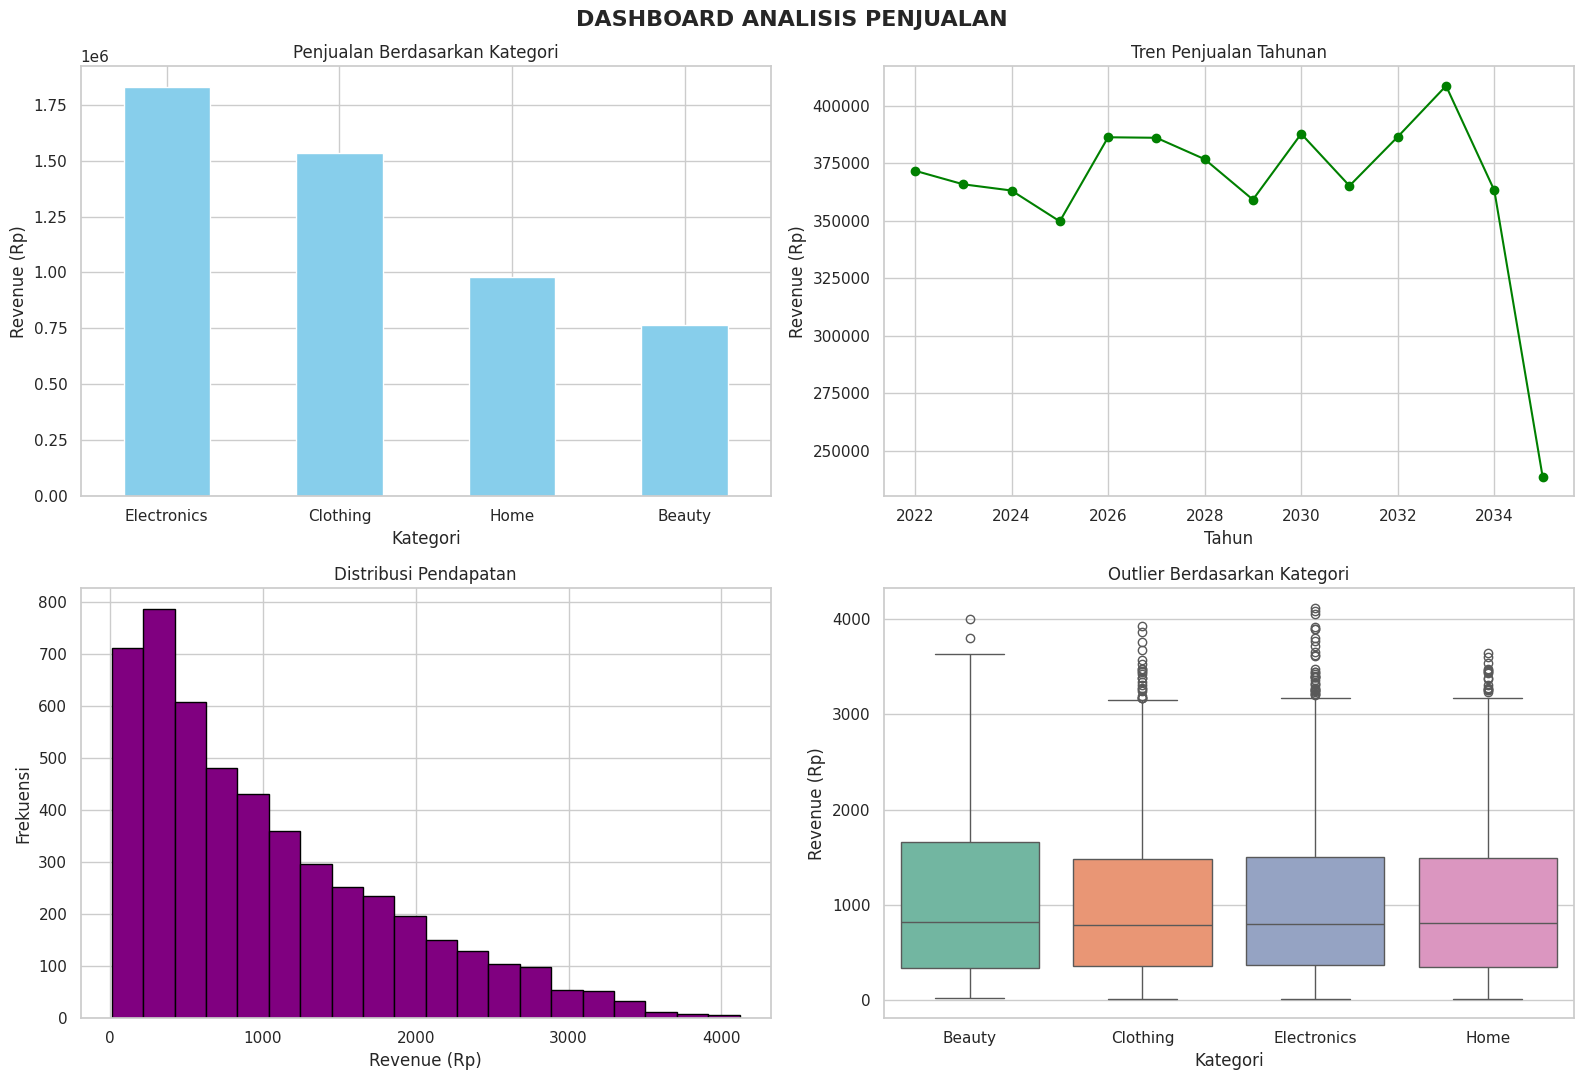

In [17]:
# Membuat dashboard 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Grafik 1: Bar Chart
penjualan_kategori.plot(
    kind='bar',
    ax=axes[0, 0],
    color='skyblue'
)
axes[0, 0].set_title('Penjualan Berdasarkan Kategori')
axes[0, 0].set_xlabel('Kategori')
axes[0, 0].set_ylabel('Revenue (Rp)')
axes[0, 0].tick_params(axis='x', rotation=0)

# Grafik 2: Line Chart
axes[0, 1].plot(
    penjualan_tahunan.index,
    penjualan_tahunan.values,
    marker='o',
    color='green'
)
axes[0, 1].set_title('Tren Penjualan Tahunan')
axes[0, 1].set_xlabel('Tahun')
axes[0, 1].set_ylabel('Revenue (Rp)')

# Grafik 3: Histogram
axes[1, 0].hist(
    df['revenue'],
    bins=20,
    color='purple',
    edgecolor='black'
)
axes[1, 0].set_title('Distribusi Pendapatan')
axes[1, 0].set_xlabel('Revenue (Rp)')
axes[1, 0].set_ylabel('Frekuensi')

# Grafik 4: Boxplot
sns.boxplot(
    data=df,
    x='product_category',
    y='revenue',
    hue='product_category',
    palette='Set2',
    legend=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Outlier Berdasarkan Kategori')
axes[1, 1].set_xlabel('Kategori')
axes[1, 1].set_ylabel('Revenue (Rp)')

plt.suptitle(
    'DASHBOARD ANALISIS PENJUALAN',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

**Laporan Rekomendasi**

Berdasarkan hasil analisis dashboard penjualan, dapat disimpulkan bahwa kategori Electronics merupakan penyumbang pendapatan terbesar, yaitu sekitar Rp1.830.000, diikuti Clothing sebesar Rp1.530.000. Sementara itu, kategori Home dan Beauty memiliki pendapatan yang lebih rendah. Oleh karena itu, perusahaan disarankan untuk mempertahankan ketersediaan stok produk Electronics dan Clothing karena kedua kategori tersebut memiliki kontribusi pendapatan paling besar. Perusahaan juga perlu melakukan evaluasi terhadap produk Home dan Beauty agar dapat meningkatkan daya tarik serta jumlah pembeli.

Selain itu, berdasarkan grafik tren penjualan tahunan, pendapatan mengalami fluktuasi dan mencapai titik tertinggi pada tahun 2033. Namun, terdapat penurunan yang cukup tajam pada tahun 2035. Perusahaan perlu mengevaluasi penyebab penurunan tersebut, misalnya melalui pemeriksaan strategi pemasaran, perubahan permintaan konsumen, dan ketersediaan produk.

Dari hasil distribusi pendapatan, sebagian besar transaksi menghasilkan pendapatan relatif rendah. Oleh karena itu, perusahaan dapat menerapkan strategi promosi seperti diskon pembelian dalam jumlah tertentu, paket bundling, dan program loyalitas pelanggan untuk meningkatkan nilai transaksi. Hasil analisis outlier juga menunjukkan adanya beberapa transaksi dengan pendapatan sangat tinggi. Transaksi tersebut dapat dijadikan bahan evaluasi untuk mengetahui produk yang memiliki potensi keuntungan lebih besar.

Dengan demikian, perusahaan disarankan untuk mempertahankan kategori unggulan, meningkatkan promosi pada kategori dengan pendapatan rendah, serta melakukan evaluasi penjualan secara berkala. Strategi tersebut diharapkan dapat meningkatkan pendapatan dan menjaga kestabilan pertumbuhan bisnis di masa mendatang.